# 06 — Compare models and evaluate next-week surge prediction

**One-time setup in this notebook’s selected kernel:** run `%pip install -r requirements.txt` in a temporary code cell, then restart the kernel. Installing packages in a different terminal Python does not install them in this kernel. On macOS, if LightGBM reports `libomp.dylib` missing, run `brew install libomp` in Terminal.

**Run this notebook:** after 01–05, select **Run All**. It uses the same remembered run automatically. Missing expanding-window preparation is generated from the local source. Progress appears below, and results are displayed in this notebook.

If this run already has a saved model, 06 verifies and reuses it. To start a complete new reproduction, Run All in Notebook 01, then continue 02–06. No folder or mode edits are needed. A partial saved run must be recovered; it is never silently replaced.

**Research question:** does the combined price-history, item/location, coverage and seasonal model improve on simple baselines under expanding-window evaluation? This comparison does not isolate the contribution of history alone.

The April–June 2026 test has already been inspected. Rebuilding a missing model is a **reproduction**, not fresh independent validation. The fixed 10% label and classifier score cutoff are separate. Weighted scores are uncalibrated. Do not tune against reproduced test results or claim demonstrated affordability benefits.

For metadata-only holdout changes, reuse can restore the exact original settings only after all other frozen artifacts pass verification. Changed data still stops execution. No source download is needed to reuse a local saved run.


New runs use the numerically safe threshold comparison recorded by 05. Reusing a pre-correction model retains its original strict labels and baseline rule; it is not silently relabelled. For a complete new execution, start with Run All in Notebook 01.

The source-quality audit is optional: missing or mismatched weekly audit data is reported as unavailable, and does not prevent viewing the verified main evaluation. A changed model, changed prepared input, missing essential result or incompatible experiment still stops execution with the affected file paths.

Saved main results describe the last local run. Quote bootstrap intervals only after their supplementary cell has executed. Reuse mode generates them from the verified frozen model and inputs without retraining.

**Role in the final system:** this notebook preserves the original 2025-trained reference experiment. Its test results belong to that model. The longer-history comparison is in `research/12_longer_history_experiment.ipynb`; Notebook 08 uses that candidate for dashboard exports when a verified completed run exists. Reopen 06 to inspect the original experiment, not to replace it. Sections 8–11 are supporting analyses rather than extra model-selection steps.


## 1. Imports and experiment settings
Only `pricecatcher_config.py` is needed beside the notebooks. The repeated modelling calculations are defined below, with no separate modelling module. Keep the original eight candidates, seed and settings for the completed experiment. `prepare.py` is an optional convenience runner for 01–05, not required when running the notebooks interactively.

New preparations identify the content of the integrated data and lookup files independently of manifest timestamps. Reuse always verifies exact saved inputs first. Legacy manifest differences are recorded as unresolved provenance, not silently declared equivalent.


In [1]:
import json
import os
import sys
import hashlib
from pathlib import Path
from importlib import metadata, reload, util
from time import perf_counter

# Check the kernel's packages before starting any preparation subprocess.
required_modules = ["nbformat", "nbclient", "ipykernel", "joblib", "numpy", "pandas",
                    "matplotlib", "sklearn", "pyarrow"]
missing_modules = [name for name in required_modules if util.find_spec(name) is None]
if missing_modules:
    raise ModuleNotFoundError(
        f"This notebook kernel ({sys.executable}) is missing: {', '.join(missing_modules)}. "
        "Run %pip install -r requirements.txt in a notebook cell, then Restart Kernel and Run All."
    )

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay

import pricecatcher_config as cfg
cfg = reload(cfg)

# Automatic: continue this run, reusing its saved model when present.
RUN_MODE = "auto"
if RUN_MODE not in {"auto", "reuse", "train"}:
    raise ValueError("RUN_MODE must be 'auto', 'reuse' or 'train'.")

SEED = 42
N_JOBS = 2
TREES = 150
original_dir, reproduction_dir = cfg.MODEL_DIRS
OUTPUT_DIR = original_dir
if RUN_MODE in {"auto", "reuse"}:
    if any((original_dir / name).exists() for name in ["best_model.joblib", "model_manifest.json"]):
        RUN_MODE = "reuse"
    elif any((reproduction_dir / name).exists() for name in ["best_model.joblib", "model_manifest.json"]):
        RUN_MODE = "reuse"
        OUTPUT_DIR = reproduction_dir
    elif RUN_MODE == "auto":
        RUN_MODE = "train"
        OUTPUT_DIR = reproduction_dir
        print("No saved model found. Running the fixed experiment as a reproduction of an exposed test period.")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FOLDS = ["fold_1", "fold_2", "fold_3"]
CANDIDATES = {
    "lr_c01": ("Logistic Regression", {"C": 0.1}),
    "lr_c1": ("Logistic Regression", {"C": 1.0}),
    "rf_depth8": ("Random Forest", {"max_depth": 8}),
    "rf_depth16": ("Random Forest", {"max_depth": 16}),
    "xgb_depth3": ("XGBoost", {"max_depth": 3}),
    "xgb_depth5": ("XGBoost", {"max_depth": 5}),
    "lgb_leaves15": ("LightGBM", {"num_leaves": 15}),
    "lgb_leaves31": ("LightGBM", {"num_leaves": 31}),
}
print("Python:", sys.executable)
print("Data folder:", cfg.PROJECT_ROOT)
print("Mode:", RUN_MODE)
print("Candidates:", len(CANDIDATES), "| Tree iterations:", TREES, "| Outputs:", OUTPUT_DIR)

SUPPLEMENT_DIR = OUTPUT_DIR / "supplementary"
SUPPLEMENT_DIR.mkdir(parents=True, exist_ok=True)
if RUN_MODE == "train" and (OUTPUT_DIR / "best_model.joblib").exists():
    raise ValueError("A frozen model already exists. Use reuse mode, or a separate PRICECATCHER_DATA_DIR for a new study.")
if RUN_MODE == "reuse" and not (OUTPUT_DIR / "model_manifest.json").exists():
    raise FileNotFoundError(f"Saved manifest missing: {OUTPUT_DIR / 'model_manifest.json'}. Use auto when no saved model exists; if a model file is present, restore its matching original manifest.")


No saved model found. Running the fixed experiment as a reproduction of an exposed test period.
Python: /usr/local/bin/python3.12
Data folder: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240
Mode: train
Candidates: 8 | Tree iterations: 150 | Outputs: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/06_models_reproduction


### Input checks and feature selection

In [ ]:
# Shared modelling calculations — Input checks and feature selection
# Shared modelling calculations
import json
import hashlib
import joblib
import pricecatcher_config as cfg
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def load_experiment(project_root, name, dates):
    """Load train/validation only. Test is deliberately loaded later in the notebook."""
    folder = Path(project_root) / "experiments" / name / "05_modelling"
    if not (folder / "experiment_settings.json").exists():
        raise FileNotFoundError(f"Missing {name} preparation. Run python prepare.py --experiment all first.")
    settings = json.loads((folder / "experiment_settings.json").read_text())
    if tuple(settings[key] for key in ["train_end", "validation_end", "test_end"]) != tuple(dates):
        raise ValueError(f"{name}: preparation dates differ from configuration; rerun 02–05.")
    if settings["preparation"]["experiment"] != name:
        raise ValueError(f"{name}: experiment metadata mismatch.")
    frames = {}
    for split in ["train", "validation"]:
        frames[split] = check_frame(pd.read_parquet(folder / f"{split}.parquet"), settings, split)
    if frames["train"].surge_label.nunique() != 2:
        raise ValueError(f"{name}: training needs both classes. Inspect the coverage/label audits.")
    return folder, settings, frames


def check_frame(frame, settings, split):
    """Validate the modelling contract and time horizon without changing any rows."""
    features = settings["feature_columns"]
    required = features + ["surge_label", "week_start", "next_week_end", "item", "unit"]
    declared = settings["numeric_features"] + settings["categorical_features"]
    if set(declared) != set(features) or len(declared) != len(features):
        raise ValueError("Numeric/categorical columns must partition the declared features exactly.")
    if len(features) != len(set(features)) or any(c.startswith("next_") or c in ["surge_label", "split"] for c in features):
        raise ValueError("Invalid feature list: identifiers/outcomes must not enter X.")
    if frame.empty or set(required) - set(frame.columns):
        raise ValueError(f"{split}: empty data or missing modelling columns.")
    if frame.surge_label.isna().any() or not frame.surge_label.isin([0, 1]).all():
        raise ValueError(f"{split}: labels must be observed 0/1 values.")
    frame = frame.copy()
    for column in ["week_start", "next_week_end"]:
        frame[column] = pd.to_datetime(frame[column])
    if frame[["week_start", "next_week_end"]].isna().any().any():
        raise ValueError("Missing split dates.")
    if not frame.week_start.dt.dayofweek.eq(0).all() or not frame.next_week_end.eq(frame.week_start + pd.Timedelta(days=13)).all():
        raise ValueError("Expected Monday-start weeks and exact next-week outcome horizons.")
    upper = pd.Timestamp(settings[{"train": "train_end", "validation": "validation_end", "test": "test_end"}[split]])
    if not frame.next_week_end.le(upper).all():
        raise ValueError(f"{split}: outcome crosses its cutoff.")
    if split != "train":
        lower = pd.Timestamp(settings["train_end" if split == "validation" else "validation_end"])
        if not (frame.week_start + pd.Timedelta(days=6)).gt(lower).all():
            raise ValueError(f"{split}: prediction overlaps the earlier split.")
    keys = ["item_code", "state", "district", "premise_type", "week_start"]
    if frame.duplicated(keys).any():
        raise ValueError(f"{split}: duplicate local series/week rows.")
    if np.isinf(frame[settings["numeric_features"]].to_numpy(dtype=float)).any():
        raise ValueError("Infinite numeric features; inspect preparation.")
    return frame


def model_inputs(frame, settings):
    """Select the whitelist; normalise categorical types without learning from data."""
    X = frame[settings["feature_columns"]].copy()
    for column in settings["categorical_features"]:
        X[column] = X[column].astype("string").fillna("__missing__").astype(str)
    return X



### Pipelines, metrics and baselines

In [ ]:
# Shared modelling calculations — Pipelines, metrics and baselines
def build_pipeline(family, parameters, settings, y_train, *, seed=42, n_jobs=2, trees=150):
    """A fresh preprocessor and estimator for every candidate/fold."""
    numeric_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True))]
    if family == "Logistic Regression":
        numeric_steps.append(("scale", StandardScaler()))
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), settings["numeric_features"]),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), settings["categorical_features"]),
    ], sparse_threshold=1.0)
    # No SMOTE: weighting uses this training fold only and preserves observed categories.
    if family == "Logistic Regression":
        model = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=seed, **parameters)
    elif family == "Random Forest":
        model = RandomForestClassifier(n_estimators=trees, min_samples_leaf=10,
            class_weight="balanced_subsample", random_state=seed, n_jobs=n_jobs, **parameters)
    elif family == "XGBoost":
        from xgboost import XGBClassifier
        positives = int(np.asarray(y_train).sum())
        if not 0 < positives < len(y_train):
            raise ValueError("XGBoost weighting requires both training classes.")
        model = XGBClassifier(n_estimators=trees, learning_rate=.05, subsample=.8,
            colsample_bytree=.8, tree_method="hist", eval_metric="logloss",
            scale_pos_weight=(len(y_train) - positives) / positives,
            random_state=seed, n_jobs=n_jobs, **parameters)
    elif family == "LightGBM":
        from lightgbm import LGBMClassifier
        model = LGBMClassifier(n_estimators=trees, learning_rate=.05, min_child_samples=30,
            colsample_bytree=.8, class_weight="balanced", verbosity=-1,
            random_state=seed, n_jobs=n_jobs, **parameters)
    else:
        raise ValueError(f"Unknown model family: {family}")
    return Pipeline([("preprocess", preprocessing), ("model", model)])


def evaluate(y, scores, predictions):
    """AP is sklearn average precision, not trapezoidal PR-AUC. Undefined AP is NaN."""
    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)
    predictions = np.asarray(predictions, dtype=int)
    if len(y) == 0 or len(scores) != len(y) or len(predictions) != len(y) or not np.isfinite(scores).all():
        raise ValueError("Metrics need aligned nonempty labels, finite scores and predictions.")
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()
    has_positives = bool(y.sum())
    return {"rows": len(y), "positives": int(y.sum()), "prevalence": float(y.mean()),
            "predicted_surges": int(predictions.sum()),
            "average_precision": float(average_precision_score(y, scores)) if len(np.unique(y)) == 2 else np.nan,
            "precision": float(precision_score(y, predictions, zero_division=0)),
            "recall": float(recall_score(y, predictions, zero_division=0)) if has_positives else np.nan,
            "f1": float(f1_score(y, predictions, zero_division=0)) if has_positives else np.nan,
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def choose_cutoff(y_validation, scores):
    """Maximise validation F1; break ties with the highest cutoff (fewer alerts)."""
    if len(np.unique(y_validation)) != 2:
        raise ValueError("Cutoff selection needs both validation classes. Inspect labels; do not use test to choose it.")
    precision, recall, cutoffs = precision_recall_curve(y_validation, scores)
    f1 = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
                   out=np.zeros(len(cutoffs)), where=(precision[:-1] + recall[:-1]) > 0)
    return float(cutoffs[np.flatnonzero(np.isclose(f1, f1.max(), rtol=0, atol=1e-12))[-1]])


def baseline_scores(frame, surge_threshold, tolerance_pct=0.0):
    """A constant classifier and a fixed current-change rule, with no fitted inputs."""
    current_change = frame["weekly_price_change_pct"].to_numpy(dtype=float)
    if not np.isfinite(current_change).all():
        raise ValueError("The current-change baseline requires the prior-week price eligibility rule.")
    return {
        "Always no surge": (np.zeros(len(frame)), np.zeros(len(frame), dtype=int)),
        "Current-change rule": (current_change, cfg.surge_mask(current_change, surge_threshold, tolerance_pct).astype(int)),
    }


def grouped_metrics(frame, scores, predictions, level):
    """Report support and undefined metrics explicitly for each geography/food group."""
    results = []
    for group, positions in frame.groupby(level, sort=True).indices.items():
        group = group if isinstance(group, tuple) else (group,)
        results.append({**dict(zip(level, group)), **evaluate(frame.iloc[positions].surge_label,
                        np.asarray(scores)[positions], np.asarray(predictions)[positions])})
    return pd.DataFrame(results)


def food_group_scores(training, frame):
    """Training-only prevalence; unseen groups fall back to the overall training rate."""
    rates = training.groupby("project_group")["surge_label"].mean()
    return frame["project_group"].map(rates).fillna(training["surge_label"].mean()).to_numpy(dtype=float)



### Frozen checkpoint saving and reuse

In [ ]:
# Shared modelling calculations — Frozen checkpoint saving and reuse
def write_json(path, value):
    """Replace JSON only after the complete file has been written."""
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2))
    temporary.replace(path)


def save_frozen_model(pipeline, selection, manifest, output_dir):
    """Activate the model LAST, so a visible model always has recovery metadata."""
    model_path = output_dir / "best_model.joblib"
    if model_path.exists():
        raise ValueError("A frozen model already exists. Use reuse mode.")
    temporary = model_path.with_suffix(".joblib.tmp")
    joblib.dump(pipeline, temporary)
    with temporary.open("rb") as handle:
        manifest["model_sha256"] = hashlib.file_digest(handle, "sha256").hexdigest()
    manifest["selection"] = selection
    manifest["run_status"] = "evaluation_pending"
    write_json(output_dir / "selection.json", selection)
    write_json(output_dir / "model_manifest.json", manifest)
    temporary.replace(model_path)


def original_settings_bytes(path, manifest):
    """Recover metadata only when it reproduces the EXACT originally recorded file."""
    settings = json.loads(path.read_text())
    if "holdout_preparation" not in manifest:
        return None
    settings["preparation"] = manifest["holdout_preparation"]
    candidate = json.dumps(settings, indent=2).encode("utf-8")
    expected = manifest["input_sha256"].get("holdout/experiment_settings.json")
    return candidate if hashlib.sha256(candidate).hexdigest() == expected else None


def verify_saved_run(output_dir, project_root):
    """Verify everything before restoring a provably original metadata file."""
    manifest = json.loads((output_dir / "model_manifest.json").read_text())
    model_path = output_dir / "best_model.joblib"
    if not model_path.exists():
        raise FileNotFoundError(f"Saved model missing: {model_path}. Restore your original 06_models folder; no download or retraining is needed for reuse.")
    with model_path.open("rb") as handle:
        if hashlib.file_digest(handle, "sha256").hexdigest() != manifest["model_sha256"]:
            raise ValueError("Saved model changed. Restore the original completed run.")
    if manifest.get("run_status", "completed") not in {"completed", "evaluation_pending"}:
        raise ValueError("Unknown saved run status. Restore the original manifest.")
    selection = json.loads((output_dir / "selection.json").read_text())
    if selection != manifest["selection"]:
        raise ValueError("Selection differs from the saved manifest. Restore the original selection.")

    recovery = None
    changed = []
    missing = []
    for relative_path, expected_hash in manifest["input_sha256"].items():
        experiment, filename = relative_path.split("/", 1)
        path = project_root / "experiments" / experiment / "05_modelling" / filename
        if not path.is_file():
            missing.append(str(path))
            continue
        with path.open("rb") as handle:
            actual_hash = hashlib.file_digest(handle, "sha256").hexdigest()
        if actual_hash == expected_hash:
            continue
        candidate = original_settings_bytes(path, manifest) if relative_path == "holdout/experiment_settings.json" else None
        if candidate is not None:
            recovery = (path, candidate)
        else:
            changed.append(relative_path)
    if missing:
        raise FileNotFoundError("Frozen inputs missing: " + ", ".join(missing)
                                + ". Restore the original prepared folder. No files were repaired; use --rerun-all for a separate full reproduction.")
    if changed:
        raise ValueError("Prepared input changed: " + ", ".join(changed)
                         + f". No files were repaired. Restore the original snapshot under {project_root / 'experiments'}; do not retrain to bypass this check.")

    # Only a byte-identical original settings file can be restored, and only
    # after the model, selection and EVERY other frozen input have passed.
    if recovery is not None:
        from datetime import datetime
        path, candidate = recovery
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
        backup = path.with_name(f"experiment_settings.before_restore_{stamp}.json")
        backup.write_bytes(path.read_bytes())
        temporary = path.with_suffix(".json.tmp")
        temporary.write_bytes(candidate)
        temporary.replace(path)
        print("Restored byte-identical original holdout settings. Backup:", backup)
        print("Saved model, manifest hashes and Parquet files were preserved.")
    return manifest, selection



### Source provenance and descriptive uncertainty

In [ ]:
# Shared modelling calculations — Source provenance and descriptive uncertainty
def source_snapshot_status(experiments, mode):
    """Compare content when available; legacy run hashes alone cannot prove changed prices."""
    manifest_hashes = {name: s["preparation"]["source_manifest_sha256"] for name, s in experiments.items()}
    content_hashes = {name: s["preparation"].get("source_snapshot_sha256") for name, s in experiments.items()}
    known_content = {value for value in content_hashes.values() if value}
    if all(content_hashes.values()) and len(known_content) == 1:
        status = "matching_content_snapshot"
    elif len(set(manifest_hashes.values())) == 1 and len(known_content) <= 1:
        status = "matching_legacy_manifest"
    else:
        if mode == "train":
            details = ", ".join(f"{name}={value[:12]}" for name, value in manifest_hashes.items())
            raise ValueError("Source snapshots are not consistently identified: " + details
                             + ". For a new study, integrate once and prepare all folds in a separate data folder.")
        status = "historical_source_consistency_unresolved"
        print("PROVENANCE NOTE: saved model and input hashes were verified against the completed run, "
              "but historical source manifests differ. A timestamp may explain this; identical source data "
              "has not been established. Original results are preserved, not validated as a consistent-source study.")
    return {"status": status, "manifest_hashes": manifest_hashes,
            "content_snapshot_hashes": content_hashes}



def week_bootstrap(frame, prediction_sets, selected_name, *, repeats=300, seed=42):
    """Resample whole weeks; keep model choices and predictions fixed and paired."""
    if selected_name not in prediction_sets or repeats < 20:
        raise ValueError("Bootstrap needs a selected prediction set and at least 20 repeats.")
    if frame["week_start"].isna().any():
        raise ValueError("Bootstrap needs an observed week for every row.")
    groups = list(frame.groupby("week_start", sort=True).indices.values())
    y = frame.surge_label.to_numpy(dtype=int)
    predictions = {name: (np.asarray(scores), np.asarray(alerts))
                   for name, (scores, alerts) in prediction_sets.items()}
    metrics = ["average_precision", "precision", "recall", "f1"]

    def measure(positions):
        results = {name: evaluate(y[positions], scores[positions], alerts[positions])
                   for name, (scores, alerts) in predictions.items()}
        values = {(name, metric): result[metric] for name, result in results.items() for metric in metrics}
        for baseline in results:
            if baseline != selected_name:
                for metric in ["average_precision", "f1"]:
                    values[(f"{selected_name} minus {baseline}", metric)] = (
                        results[selected_name][metric] - results[baseline][metric])
        return values

    # Validate the complete arrays before any sampling; no refitting or tuning occurs.
    for scores, alerts in predictions.values():
        evaluate(y, scores, alerts)
    point = measure(np.arange(len(frame)))
    samples = []
    rng = np.random.default_rng(seed)
    if len(groups) >= 2:
        for _ in range(repeats):
            positions = np.concatenate([groups[i] for i in rng.integers(len(groups), size=len(groups))])
            samples.append(measure(positions))
    rows = []
    for (name, metric), estimate in point.items():
        values = np.asarray([sample[(name, metric)] for sample in samples])
        values = values[np.isfinite(values)]
        lower, upper = np.quantile(values, [.025, .975]) if len(values) >= 20 else (np.nan, np.nan)
        rows.append({"comparison": name, "metric": metric, "estimate": estimate,
            "lower_95": lower, "upper_95": upper, "usable_repeats": len(values),
            "requested_repeats": repeats, "test_weeks": len(groups)})
    return pd.DataFrame(rows)

## 2. Declare metrics and success criteria before training

**Primary selection metric:** mean **average precision (AP)** across the three expanding validation folds. AP here means `sklearn.metrics.average_precision_score`, a step-weighted precision–recall summary, **not trapezoidal PR-AUC**. Report its fold standard deviation as descriptive variability, not a confidence interval. Ties use lower AP standard deviation, then candidate name.

**Secondary metrics:** precision, recall, F1 and confusion counts. During fold comparison ML cutoffs stay at 0.5; final cutoff optimisation happens only after model selection. Precision with no predicted positives is reported as 0. Recall/F1 with no observed positives and AP without both classes are reported as undefined. Group support must accompany scores.

**Baselines:** always predict no surge; and predict next-week surge when this week's observed price increase is already at least the fixed surge threshold. The latter's AP uses current percentage change as its ranking score. Constant-score AP equals prevalence when both classes exist.

**Measurable criteria:** (1) selected model's mean fold AP exceeds both baselines; (2) final test AP exceeds both test baselines; (3) final test F1 exceeds both baseline F1 scores. Show which criteria are met, even when the model loses. These are relative technical benchmarks, not promised numeric scores or evidence of economic impact. Decide any stakeholder minimum recall/precision before accessing test results.


In [3]:
# New auto reproductions can prepare missing folds from already integrated local data.
# This is needed even when 01–05 were previously run for holdout only.
missing_folds = []
for name in FOLDS + ["holdout"]:
    path = cfg.PROJECT_ROOT / "experiments" / name / "05_modelling" / "experiment_settings.json"
    required = [path.parent / filename for filename in ["train.parquet", "validation.parquet", "latest_prediction_inputs.parquet"]]
    if name == "holdout":
        required.append(path.parent / "test.parquet")
    if (not path.is_file() or not all(file.is_file() for file in required)
            or json.loads(path.read_text())["preparation"].get("schema_version") != cfg.PREPARATION_SETTINGS["schema_version"]):
        missing_folds.append(name)
if RUN_MODE == "train" and missing_folds:
    if not cfg.STAGE1_COMBINED_PARQUET.exists():
        raise FileNotFoundError("Local integrated data is missing. Run 01–05 first, or python prepare.py --experiment all.")
    import os
    import sys
    import subprocess
    print("Preparing missing/outdated experiments from local integrated data:", ", ".join(missing_folds))
    subprocess.run([sys.executable, str(Path(cfg.__file__).parent / "prepare.py"), "--experiment", "all"],
                   env={**os.environ, "PRICECATCHER_DATA_DIR": str(cfg.PROJECT_ROOT)}, check=True)

# Verify frozen inputs FIRST in reuse mode; this never refits the model.
if RUN_MODE == "reuse":
    saved_manifest, selection = verify_saved_run(OUTPUT_DIR, cfg.PROJECT_ROOT)
    missing_results = [str(OUTPUT_DIR / filename) for filename in
        ["fold_metrics.csv", "fold_summary.csv", "validation_metrics.csv"] if not (OUTPUT_DIR / filename).is_file()]
    if missing_results:
        raise FileNotFoundError("Saved evaluation files missing: " + ", ".join(missing_results)
                                + ". Restore these results, or use python prepare.py --rerun-all for a separate reproduction.")
    if saved_manifest.get("run_status") == "evaluation_pending":
        print("Resuming pending evaluation with the frozen model and cutoff; no fitting.")
# Write main results for a new run or an interrupted run, never a completed reuse.
SAVE_MAIN = RUN_MODE == "train" or saved_manifest.get("run_status") == "evaluation_pending"
# Read metadata only: no test rows or labels are loaded here.
experiment_settings = {}
for name in FOLDS + ["holdout"]:
    path = cfg.PROJECT_ROOT / "experiments" / name / "05_modelling" / "experiment_settings.json"
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}. Run python prepare.py --experiment all first.")
    experiment_settings[name] = json.loads(path.read_text())

reference = experiment_settings["holdout"]
if RUN_MODE == "train":
    source = cfg.verify_source_snapshot()
    if reference["preparation"].get("source_snapshot_sha256") != source["source_snapshot_sha256"]:
        raise ValueError("Prepared inputs do not match the current source snapshot. Prepare a new study consistently.")
# Learned exclusions/bounds may differ; the target, source snapshot and shared policies must agree.
variable_keys = {"experiment", "train_end", "validation_end", "test_end", "evaluation_end",
                 "apply_documented_exclusions"}
label_policy_keys = {"schema_version", "label_comparison", "label_tolerance_pct"}
SURGE_TOLERANCE = reference["preparation"].get("label_tolerance_pct", 0.0)
legacy_labels = RUN_MODE == "reuse" and "label_tolerance_pct" not in reference["preparation"]
# Reuse follows the verified saved experiment, not today's editable defaults.
expected_preparation = cfg.PREPARATION_SETTINGS if RUN_MODE == "train" else reference["preparation"]
shared_keys = set(expected_preparation) - variable_keys - {"source_manifest_sha256", "source_snapshot_sha256"}
if legacy_labels:
    shared_keys -= label_policy_keys
    print("Reusing the saved strict-comparison label rule. Use --rerun-all for the numerical correction in a new run.")
for name, settings in experiment_settings.items():
    preparation = settings["preparation"]
    if any(preparation.get(key) != expected_preparation[key] for key in shared_keys):
        raise ValueError(f"{name}: preparation policies do not match this experiment. Use --rerun-all for a consistent separate reproduction.")
    if preparation.get("label_tolerance_pct", 0.0) != SURGE_TOLERANCE:
        raise ValueError(f"{name}: mixed surge-label comparison rules. Prepare a consistent new run.")
    for key in ["feature_columns", "numeric_features", "categorical_features", "target_status", "surge_threshold_pct"]:
        if settings[key] != reference[key]:
            raise ValueError(f"{name}: incompatible {key}.")
    if name in FOLDS and preparation["apply_documented_exclusions"]:
        raise ValueError("Early folds must retain retrospective manual exceptions whose review dates are unknown.")

source_provenance = source_snapshot_status(experiment_settings, RUN_MODE)
(SUPPLEMENT_DIR / "source_provenance.json").write_text(json.dumps(source_provenance, indent=2))
print("Source provenance:", source_provenance["status"])
SURGE_THRESHOLD = reference["surge_threshold_pct"]
display(pd.DataFrame([
    {"experiment": name, "train_end": s["train_end"], "validation_end": s["validation_end"],
     "test_end": s["test_end"], "manual_exclusions": s["review_policy"]["documented_training_records_excluded"]}
    for name, s in experiment_settings.items()
]))


Preparing missing/outdated experiments from local integrated data: fold_1, fold_2, fold_3
fold_1: 01_integrate_pricecatcher.ipynb
fold_1: 02_data_understanding_and_quality.ipynb
fold_1: 03_cleaning_and_outliers.ipynb
fold_1: 04_weekly_aggregation.ipynb
fold_1: 05_features_and_labels.ipynb
Completed. Outputs: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/experiments/fold_1
fold_2: 02_data_understanding_and_quality.ipynb
fold_2: 03_cleaning_and_outliers.ipynb
fold_2: 04_weekly_aggregation.ipynb
fold_2: 05_features_and_labels.ipynb
Completed. Outputs: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/experiments/fold_2
fold_3: 02_data_understanding_and_quality.ipynb
fold_3: 03_cleaning_and_outliers.ipynb
fold_3: 04_weekly_aggregation.ipynb
fold_3: 05_features_and_labels.ipynb
Completed. Outputs: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/experiments/fold_3
holdout: existing preparation reused at /Users/a

,experiment,train_end,validation_end,test_end,manual_exclusions
0,fold_1,2025-05-31,2025-07-31,NaN,0
1,fold_2,2025-07-31,2025-09-30,NaN,0
2,fold_3,2025-09-30,2025-12-31,NaN,0
3,holdout,2025-12-31,2026-03-31,2026-06-30,6


## 3. Compare candidates on expanding folds

Each fit gets a **new** median imputer, missingness indicators and categorical encoder trained on that fold alone. Logistic Regression additionally scales numeric features using training statistics. Missing categorical values use a fixed token; unseen categories are ignored by one-hot encoding. Numeric features entirely missing in training are retained by the imputer. Item codes are categories.

Class weighting is derived from training labels only. No evaluation labels influence training weights, preprocessing, tree counts or early stopping. Validation inputs may contain price history observed by their own prediction dates, as intended for weekly prediction. Only one fold is held in memory at a time. The preparation policy intentionally keeps the retrospective manual exceptions in the early folds.


In [4]:
if RUN_MODE == "train":
    fold_rows = []
    for fold in FOLDS:
        folder, settings, frames = load_experiment(cfg.PROJECT_ROOT, fold, cfg.EXPERIMENTS[fold])
        train, validation = frames["train"], frames["validation"]
        y_train = train.surge_label.astype(int)
        y_validation = validation.surge_label.astype(int)
        if y_validation.nunique() != 2:
            raise ValueError(f"{fold}: AP comparison needs both validation classes; inspect the label audits.")
        X_train = model_inputs(train, settings)
        X_validation = model_inputs(validation, settings)
        print(f"{fold}: {len(train):,} training rows; {len(validation):,} validation rows")

        for name, (scores, predictions) in baseline_scores(validation, SURGE_THRESHOLD, SURGE_TOLERANCE).items():
            fold_rows.append({"fold": fold, "candidate": name, "family": "Baseline", "fit_seconds": 0.0,
                              **evaluate(y_validation, scores, predictions)})
        for name, (family, parameters) in CANDIDATES.items():
            pipeline = build_pipeline(family, parameters, settings, y_train,
                                      seed=SEED, n_jobs=N_JOBS, trees=TREES)
            started = perf_counter()
            pipeline.fit(X_train, y_train)
            seconds = perf_counter() - started
            scores = pipeline.predict_proba(X_validation)[:, 1]
            metrics = evaluate(y_validation, scores, scores >= 0.5)
            fold_rows.append({"fold": fold, "candidate": name, "family": family,
                              "fit_seconds": seconds, **metrics})
            print(f"  {name}: AP={metrics['average_precision']:.4f}; F1@0.5={metrics['f1']:.4f}")
            del pipeline
        del frames, train, validation, X_train, X_validation

    fold_metrics = pd.DataFrame(fold_rows)
    fold_metrics.to_csv(OUTPUT_DIR / "fold_metrics.csv", index=False)
    fold_summary = fold_metrics.groupby(["candidate", "family"]).agg(
        mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
        scored_folds=("average_precision", "count"), mean_f1=("f1", "mean"),
        mean_recall=("recall", "mean"), mean_precision=("precision", "mean"),
        total_fit_seconds=("fit_seconds", "sum"),
    ).reset_index().sort_values(["mean_ap", "std_ap", "candidate"], ascending=[False, True, True])
    fold_summary.to_csv(OUTPUT_DIR / "fold_summary.csv", index=False)
    display(fold_summary)
else:
    # Saved artifacts were already verified in the metadata preflight.
    fold_metrics = pd.read_csv(OUTPUT_DIR / "fold_metrics.csv")
    fold_summary = pd.read_csv(OUTPUT_DIR / "fold_summary.csv")
    display(fold_summary)
    print("Reusing completed fold results; no fitting performed.")


fold_1: 66,384 training rows; 31,971 validation rows
  lr_c01: AP=0.2599; F1@0.5=0.3285
  lr_c1: AP=0.2630; F1@0.5=0.3307
  rf_depth8: AP=0.2858; F1@0.5=0.3190
  rf_depth16: AP=0.2902; F1@0.5=0.3451
  xgb_depth3: AP=0.2885; F1@0.5=0.3072
  xgb_depth5: AP=0.2807; F1@0.5=0.3218
  lgb_leaves15: AP=0.2923; F1@0.5=0.3184
  lgb_leaves31: AP=0.2854; F1@0.5=0.3238
fold_2: 101,515 training rows; 31,753 validation rows
  lr_c01: AP=0.3128; F1@0.5=0.3312
  lr_c1: AP=0.3171; F1@0.5=0.3431
  rf_depth8: AP=0.3323; F1@0.5=0.3359
  rf_depth16: AP=0.3661; F1@0.5=0.4130
  xgb_depth3: AP=0.3718; F1@0.5=0.4074
  xgb_depth5: AP=0.3943; F1@0.5=0.4323
  lgb_leaves15: AP=0.3862; F1@0.5=0.4256
  lgb_leaves31: AP=0.3960; F1@0.5=0.4376
fold_3: 138,296 training rows; 54,666 validation rows
  lr_c01: AP=0.3090; F1@0.5=0.3679
  lr_c1: AP=0.3079; F1@0.5=0.3679
  rf_depth8: AP=0.3447; F1@0.5=0.3513
  rf_depth16: AP=0.3776; F1@0.5=0.3958
  xgb_depth3: AP=0.3534; F1@0.5=0.3813
  xgb_depth5: AP=0.3636; F1@0.5=0.3891
  l

,candidate,family,mean_ap,std_ap,scored_folds,mean_f1,mean_recall,mean_precision,total_fit_seconds
3,lgb_leaves31,LightGBM,0.355720,0.061089,3,0.393061,0.669978,0.282302,2.932185
2,lgb_leaves15,LightGBM,0.350969,0.051133,3,0.380040,0.685167,0.266478,2.454145
9,xgb_depth5,XGBoost,0.346202,0.058773,3,0.381055,0.667159,0.271021,2.427380
6,rf_depth16,Random Forest,0.344621,0.047516,3,0.384665,0.684012,0.268266,27.215837
8,xgb_depth3,XGBoost,0.337893,0.043773,3,0.365298,0.711530,0.249135,2.000554
7,rf_depth8,Random Forest,0.320923,0.031037,3,0.335407,0.853461,0.208770,11.024800
5,lr_c1,Logistic Regression,0.296015,0.028935,3,0.347246,0.541355,0.279305,2.575453
4,lr_c01,Logistic Regression,0.293928,0.029512,3,0.342540,0.533688,0.276557,2.135731
1,Current-change rule,Baseline,0.120974,0.026823,3,0.191330,0.193252,0.189686,0.000000
0,Always no surge,Baseline,0.106114,0.010602,3,0.000000,0.000000,0.000000,0.000000


## 4. Freeze the candidate, then use the 2026 validation period

Choose the strongest ML candidate by the prespecified fold rule; the benchmark checks can still show that a simple baseline is better. Fit that candidate through December 2025; do not fit any part of it on validation/test rows. Choose the **highest score cutoff maximising validation F1** (conservative tie-break). Validation F1 after cutoff tuning is a selection result, not an unbiased performance estimate.

The fitted pipeline is kept unchanged for final test evaluation and later predictions. We do not refit on train+validation, because that would change the score scale after choosing the cutoff. A future deployment refit needs its own later calibration/evaluation protocol.


In [5]:
if RUN_MODE == "train":
    ranked = fold_summary.loc[fold_summary.candidate.isin(CANDIDATES)].copy()
    if not ranked.scored_folds.eq(len(FOLDS)).all():
        raise ValueError("Every candidate must have AP from all folds; do not select from inconsistent subsets.")
    selected_name = ranked.iloc[0].candidate
    selected_family, selected_parameters = CANDIDATES[selected_name]
    folder, settings, frames = load_experiment(cfg.PROJECT_ROOT, "holdout", cfg.EXPERIMENTS["holdout"])
    train, validation = frames["train"], frames["validation"]
    final_pipeline = build_pipeline(selected_family, selected_parameters, settings, train.surge_label.astype(int),
                                    seed=SEED, n_jobs=N_JOBS, trees=TREES)
    final_pipeline.fit(model_inputs(train, settings), train.surge_label.astype(int))
    validation_scores = final_pipeline.predict_proba(model_inputs(validation, settings))[:, 1]
    score_cutoff = choose_cutoff(validation.surge_label.astype(int), validation_scores)
    print("Selected:", selected_name, "| Validation-selected score cutoff:", score_cutoff)

    validation_rows = [
        {"model": selected_name, "cutoff": score_cutoff,
         **evaluate(validation.surge_label, validation_scores, validation_scores >= score_cutoff)},
        {"model": selected_name + " @0.5", "cutoff": 0.5,
         **evaluate(validation.surge_label, validation_scores, validation_scores >= 0.5)},
    ]
    for name, (scores, predictions) in baseline_scores(validation, SURGE_THRESHOLD, SURGE_TOLERANCE).items():
        validation_rows.append({"model": name, **evaluate(validation.surge_label, scores, predictions)})
    validation_metrics = pd.DataFrame(validation_rows)
    validation_metrics.to_csv(OUTPUT_DIR / "validation_metrics.csv", index=False)
    display(validation_metrics)

    # Freeze model, cutoff and exact input hashes BEFORE accessing test rows.
    selection = {"candidate": selected_name, "family": selected_family, "parameters": selected_parameters,
                 "score_cutoff": score_cutoff, "selection_metric": "mean expanding-fold average precision",
                 "cutoff_rule": "maximum validation F1; highest cutoff breaks ties",
                 "seed": SEED, "n_jobs": N_JOBS, "tree_iterations": TREES,
                 "feature_columns": settings["feature_columns"], "target": settings["target"],
                 "surge_threshold_pct": SURGE_THRESHOLD, "label_tolerance_pct": SURGE_TOLERANCE, "target_status": settings["target_status"],
                 "score_interpretation": "uncalibrated model score; not verified event probability",
                 "training_end": settings["train_end"], "validation_end": settings["validation_end"],
                 "test_end": settings["test_end"], "refit_on_validation": False}
    input_hashes = {}
    for name in FOLDS + ["holdout"]:
        input_folder = cfg.PROJECT_ROOT / "experiments" / name / "05_modelling"
        files = ["experiment_settings.json", "train.parquet", "validation.parquet"]
        if name == "holdout":
            files += ["test.parquet", "latest_prediction_inputs.parquet"]
        for filename in files:
            with (input_folder / filename).open("rb") as handle:
                input_hashes[f"{name}/{filename}"] = hashlib.file_digest(handle, "sha256").hexdigest()
    versions = {}
    for package in ["pandas", "numpy", "scikit-learn", "xgboost", "xgboost-cpu", "lightgbm", "joblib"]:
        try:
            versions[package] = metadata.version(package)
        except metadata.PackageNotFoundError:
            pass  # Only one of xgboost / xgboost-cpu needs to be installed.
    code_hashes = {name: hashlib.sha256((Path(cfg.__file__).parent / name).read_bytes()).hexdigest()
                   for name in ["06_model_training_and_evaluation.ipynb", "05_features_and_labels.ipynb", "pricecatcher_config.py"]}
    manifest = {"study_status": "reproduction of an exposed test period" if OUTPUT_DIR == reproduction_dir else "configured experiment; test exposure must be reported",
                "source_provenance": source_provenance, "code_sha256": code_hashes, "selection": selection, "candidates": CANDIDATES, "folds": FOLDS,
                "input_sha256": input_hashes, "package_versions": versions,
                "holdout_preparation": settings["preparation"], "holdout_cleaning": settings["review_policy"],
                "metric_definition": "sklearn average precision; not trapezoidal PR-AUC",
                "limitations": ["Uncalibrated scores", "Observed-median labels can reflect monitoring composition",
                                "Per-group scarcity", "No demonstrated affordability or adoption outcomes"]}
    save_frozen_model(final_pipeline, selection, manifest, OUTPUT_DIR)
else:
    # Hashes were checked before loading this trusted local model.
    selected_name = selection["candidate"]
    selected_family = selection["family"]
    selected_parameters = selection["parameters"]
    score_cutoff = selection["score_cutoff"]
    frozen_dates = tuple(reference[key] for key in ["train_end", "validation_end", "test_end"])
    folder, settings, frames = load_experiment(cfg.PROJECT_ROOT, "holdout", frozen_dates)
    train, validation = frames["train"], frames["validation"]
    final_pipeline = joblib.load(OUTPUT_DIR / "best_model.joblib")
    validation_scores = final_pipeline.predict_proba(model_inputs(validation, settings))[:, 1]
    ranked = fold_summary.loc[fold_summary.candidate.eq(selected_name)].copy()
    validation_metrics = pd.read_csv(OUTPUT_DIR / "validation_metrics.csv")
    print("Reusing:", selected_name, "| Frozen score cutoff:", score_cutoff)
    display(validation_metrics)


Selected: lgb_leaves31 | Validation-selected score cutoff: 0.6006503045679725


,model,cutoff,rows,positives,prevalence,predicted_surges,average_precision,precision,recall,f1,tn,fp,fn,tp
0,lgb_leaves31,0.60065,43594,3912,0.089737,11595,0.223372,0.221820,0.657464,0.331721,30659,9023,1340,2572
1,lgb_leaves31 @0.5,0.50000,43594,3912,0.089737,15746,0.223372,0.203099,0.817485,0.325364,27134,12548,714,3198
2,Always no surge,NaN,43594,3912,0.089737,0,0.089737,0.000000,0.000000,0.000000,39682,0,3912,0
3,Current-change rule,NaN,43594,3912,0.089737,4417,0.101561,0.175685,0.198364,0.186337,36041,3641,3136,776


## 5. Final test — evaluate the frozen choice once

**Only now load April–June 2026 test rows.** No model, feature, threshold or cleaning change follows from these results. If results are weak, report that finding; further development needs a fresh untouched evaluation period. Repeatedly tuning after inspecting this section invalidates the final-test claim.

We report the selected cutoff, the fixed 0.5 reference and both baselines. AP assesses ranking independently of the classification cutoff. Scores from weighted models are not calibrated probabilities.


The checkpoint hashes all prepared files as opaque bytes before evaluation. Test rows/labels are first loaded below. A pending run resumes this same frozen choice; it does not repeat model selection.

In [6]:
test = check_frame(pd.read_parquet(folder / "test.parquet"), settings, "test")
test_scores = final_pipeline.predict_proba(model_inputs(test, settings))[:, 1]
test_predictions = (test_scores >= score_cutoff).astype(int)
test_rows = [
    {"model": selected_name, "cutoff": score_cutoff, **evaluate(test.surge_label, test_scores, test_predictions)},
    {"model": selected_name + " @0.5", "cutoff": 0.5, **evaluate(test.surge_label, test_scores, test_scores >= 0.5)},
]
for name, (scores, predictions) in baseline_scores(test, SURGE_THRESHOLD, SURGE_TOLERANCE).items():
    test_rows.append({"model": name, **evaluate(test.surge_label, scores, predictions)})
test_metrics = pd.DataFrame(test_rows)
if SAVE_MAIN:
    test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
display(test_metrics)

selected_mean_ap = float(ranked.iloc[0].mean_ap)
baseline_mean_ap = float(fold_summary.loc[fold_summary.family.eq("Baseline"), "mean_ap"].max())
baseline_test = test_metrics.loc[test_metrics.model.isin(["Always no surge", "Current-change rule"])]
criteria = pd.DataFrame([
    {"criterion": "Mean fold AP exceeds both baselines", "model_value": selected_mean_ap,
     "reference_value": baseline_mean_ap},
    {"criterion": "Test AP exceeds both baselines", "model_value": test_metrics.iloc[0].average_precision,
     "reference_value": baseline_test.average_precision.max()},
    {"criterion": "Test F1 exceeds both baselines", "model_value": test_metrics.iloc[0].f1,
     "reference_value": baseline_test.f1.max()},
])
criteria["assessable"] = criteria[["model_value", "reference_value"]].notna().all(axis=1)
criteria["met"] = pd.Series(pd.NA, index=criteria.index, dtype="boolean")
criteria.loc[criteria.assessable, "met"] = (
    criteria.loc[criteria.assessable, "model_value"] > criteria.loc[criteria.assessable, "reference_value"])
if SAVE_MAIN:
    criteria.to_csv(OUTPUT_DIR / "benchmark_checks.csv", index=False)
display(criteria)


,model,cutoff,rows,positives,prevalence,predicted_surges,average_precision,precision,recall,f1,tn,fp,fn,tp
0,lgb_leaves31,0.60065,57456,7125,0.124008,12116,0.335525,0.328904,0.559298,0.414220,42200,8131,3140,3985
1,lgb_leaves31 @0.5,0.50000,57456,7125,0.124008,16525,0.335525,0.296460,0.687579,0.414292,38705,11626,2226,4899
2,Always no surge,NaN,57456,7125,0.124008,0,0.124008,0.000000,0.000000,0.000000,50331,0,7125,0
3,Current-change rule,NaN,57456,7125,0.124008,7112,0.150528,0.225394,0.224982,0.225188,44822,5509,5522,1603


,criterion,model_value,reference_value,assessable,met
0,Mean fold AP exceeds both baselines,0.355720,0.120974,True,True
1,Test AP exceeds both baselines,0.335525,0.150528,True,True
2,Test F1 exceeds both baselines,0.414220,0.225188,True,True


## 6. Check food groups, geography and errors

Overall performance can hide weak groups or be dominated by vegetables. Export support, prevalence and confusion counts alongside metrics for each food group, state and district. Undefined group metrics stay missing; zero observed surges cannot establish positive-case detection quality. These are descriptive test breakdowns, not a new tuning step or proof of geographical fairness.


,model,breakdown,project_group,rows,positives,prevalence,predicted_surges,average_precision,precision,recall,f1,tn,fp,fn,tp,state,district
0,lgb_leaves31,project_group,Chicken,5256,180,0.034247,49,0.239998,0.244898,0.066667,0.104803,5039,37,168,12,NaN,NaN
1,lgb_leaves31,project_group,Cooking Oil,5461,1,0.000183,0,0.000903,0.000000,0.000000,0.000000,5460,0,1,0,NaN,NaN
2,lgb_leaves31,project_group,Eggs,10668,550,0.051556,1433,0.207190,0.204466,0.532727,0.295512,8978,1140,257,293,NaN,NaN
3,lgb_leaves31,project_group,Flour,2965,21,0.007083,25,0.070733,0.080000,0.095238,0.086957,2921,23,19,2,NaN,NaN
4,lgb_leaves31,project_group,Rice,982,16,0.016293,2,0.218956,1.000000,0.125000,0.222222,966,0,14,2,NaN,NaN
5,lgb_leaves31,project_group,Sugar,4652,0,0.000000,0,NaN,0.000000,NaN,NaN,4652,0,0,0,NaN,NaN
6,lgb_leaves31,project_group,Vegetables,27472,6357,0.231399,10607,0.357177,0.346564,0.578260,0.433388,14184,6931,2681,3676,NaN,NaN
183,Always no surge,project_group,Chicken,5256,180,0.034247,0,0.034247,0.000000,0.000000,0.000000,5076,0,180,0,NaN,NaN
184,Always no surge,project_group,Cooking Oil,5461,1,0.000183,0,0.000183,0.000000,0.000000,0.000000,5460,0,1,0,NaN,NaN
185,Always no surge,project_group,Eggs,10668,550,0.051556,0,0.051556,0.000000,0.000000,0.000000,10118,0,550,0,NaN,NaN


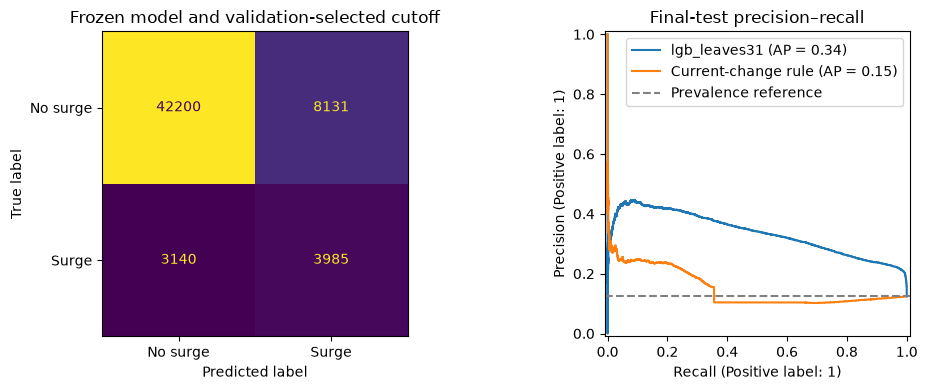

In [7]:
group_rows = []
for model_name, scores, predictions in [(selected_name, test_scores, test_predictions)] + [
    (name, scores, predictions) for name, (scores, predictions) in baseline_scores(test, SURGE_THRESHOLD, SURGE_TOLERANCE).items()
]:
    for level in [["project_group"], ["state"], ["state", "district"]]:
        table = grouped_metrics(test, scores, predictions, level)
        table.insert(0, "model", model_name)
        table.insert(1, "breakdown", "/".join(level))
        group_rows.append(table)
group_results = pd.concat(group_rows, ignore_index=True)
if SAVE_MAIN:
    group_results.to_csv(OUTPUT_DIR / "test_group_metrics.csv", index=False)
display(group_results.loc[group_results.breakdown.eq("project_group")])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(test.surge_label, test_predictions, labels=[0, 1],
    display_labels=["No surge", "Surge"], ax=axes[0], colorbar=False)
axes[0].set_title("Frozen model and validation-selected cutoff")
if test.surge_label.nunique() == 2:
    PrecisionRecallDisplay.from_predictions(test.surge_label, test_scores, name=selected_name, ax=axes[1])
    current_scores, _ = baseline_scores(test, SURGE_THRESHOLD, SURGE_TOLERANCE)["Current-change rule"]
    PrecisionRecallDisplay.from_predictions(test.surge_label, current_scores, name="Current-change rule", ax=axes[1])
    axes[1].axhline(test.surge_label.mean(), linestyle="--", color="grey", label="Prevalence reference")
    axes[1].legend()
else:
    axes[1].text(.1, .5, "PR comparison undefined: test has one class")
axes[1].set_title("Final-test precision–recall")
fig.tight_layout()
if SAVE_MAIN:
    fig.savefig(OUTPUT_DIR / "test_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()


## 7. Save auditable predictions and model provenance

Keep identifiers, dates, labels and scores so false alarms/misses can be inspected without retraining. Latest predictions use the same fitted pipeline and cutoff. These historical-snapshot scores do not imply a live dashboard.

The manifest records prepared-input, code and saved-model hashes alongside package versions. Later SHAP work should load **this saved pipeline** and its training-derived preprocessing, then precompute selected explanations for responsive dashboard display. Isolation Forest remains a separate task. Load only trusted model files; joblib stores executable Python objects.


In [8]:
if SAVE_MAIN:
    identifiers = ["item_code", "item", "unit", "project_group", "state", "district", "premise_type", "week_start", "next_week_end"]
    for name, frame, scores in [("validation", validation, validation_scores), ("test", test, test_scores)]:
        predictions = frame[identifiers + ["surge_label"]].copy()
        predictions["model_score"] = scores
        predictions["predicted_surge"] = (scores >= score_cutoff).astype(int)
        predictions.to_parquet(OUTPUT_DIR / f"{name}_predictions.parquet", index=False)

    latest = pd.read_parquet(folder / "latest_prediction_inputs.parquet")
    latest_predictions = latest[identifiers].copy()
    if len(latest):
        latest_predictions["model_score"] = final_pipeline.predict_proba(model_inputs(latest, settings))[:, 1]
        latest_predictions["predicted_surge"] = (latest_predictions.model_score >= score_cutoff).astype(int)
    else:
        latest_predictions["model_score"] = pd.Series(dtype=float)
        latest_predictions["predicted_surge"] = pd.Series(dtype=int)
        print("No supported latest-week rows. No stale local predictions substituted.")
    latest_predictions.to_parquet(OUTPUT_DIR / "latest_predictions.parquet", index=False)

    # Mark complete only after every main result/prediction export succeeded.
    manifest = json.loads((OUTPUT_DIR / "model_manifest.json").read_text())
    manifest["run_status"] = "completed"
    write_json(OUTPUT_DIR / "model_manifest.json", manifest)
    print("Saved frozen model results and prediction files to:", OUTPUT_DIR)
else:
    print("Original model, cutoff, predictions and main result files preserved.")


Saved frozen model results and prediction files to: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/06_models_reproduction


## 8. Supplementary analysis — food-group prevalence baseline
**Added after the original test was exposed.** This is not a fourth prespecified benchmark and never reselects the model, features or main cutoff.

Give each row its food group's surge frequency learned from **training only**. An unseen group uses the overall training frequency. Choose this baseline's own classification cutoff on validation only, then compare ranking and F1 on the same test rows. The baseline uses no recent price movement, so it checks whether the model adds information beyond group composition. Do not change its specification after inspecting these supplementary test results.


In [9]:
group_validation_scores = food_group_scores(train, validation)
group_test_scores = food_group_scores(train, test)
group_cutoff = choose_cutoff(validation.surge_label.astype(int), group_validation_scores)
supplementary_rows = []
for split, frame, model_scores, prevalence_scores in [
    ("validation", validation, validation_scores, group_validation_scores),
    ("test", test, test_scores, group_test_scores),
]:
    for name, scores, cutoff in [(selected_name, model_scores, score_cutoff),
                                 ("Training food-group prevalence", prevalence_scores, group_cutoff)]:
        supplementary_rows.append({"analysis": "post-hoc supplementary", "split": split,
            "model": name, "score_cutoff": cutoff, **evaluate(frame.surge_label, scores, scores >= cutoff)})
prevalence_comparison = pd.DataFrame(supplementary_rows)
prevalence_comparison.to_csv(SUPPLEMENT_DIR / "food_group_baseline.csv", index=False)
display(prevalence_comparison)


,analysis,split,model,score_cutoff,rows,positives,prevalence,predicted_surges,average_precision,precision,recall,f1,tn,fp,fn,tp
0,post-hoc supplementary,validation,lgb_leaves31,0.600650,43594,3912,0.089737,11595,0.223372,0.221820,0.657464,0.331721,30659,9023,1340,2572
1,post-hoc supplementary,validation,Training food-group prevalence,0.181707,43594,3912,0.089737,24309,0.155814,0.156979,0.975460,0.270437,19189,20493,96,3816
2,post-hoc supplementary,test,lgb_leaves31,0.600650,57456,7125,0.124008,12116,0.335525,0.328904,0.559298,0.414220,42200,8131,3140,3985
3,post-hoc supplementary,test,Training food-group prevalence,0.181707,57456,7125,0.124008,27472,0.225340,0.231399,0.892211,0.367489,29216,21115,768,6357


## 9. Supplementary analysis — validation source-quality audit
This is a **diagnostic, not a model-robustness experiment**. Keep the model and cutoff frozen. Join suspicious-record counts for the current and target weeks to validation predictions only. The target-week flags are retrospective audit evidence and never model features. Compare errors for supported pairs with/without flags and report group composition.

Flags are not confirmed source errors. Different error rates do not prove that suspicious records caused model failures. This check does not remove prices, relabel rows, retrain or use test errors to choose a cleaning policy. A future cleaning sensitivity experiment needs a separate design and untouched evaluation period.


If legacy model settings were restored exactly, newer weekly source metadata can differ. The audit still requires identical preparation policies and matching current validation prices and target labels. Any provenance difference is recorded separately; passing these checks does not prove identical historical source files or original flag assignments.

An unavailable audit is explicitly recorded as `unavailable`, with its reason. Its old supplementary CSVs are removed to avoid displaying stale audit results. Main result files are preserved. Passing model checks alone does not establish source-quality robustness.

In [10]:
weekly_path = folder.parent / "04_weekly" / "weekly_prices.parquet"
weekly_audit_status = {"status": "not_run", "reason": None}
weekly_audit_provenance = None
try:
    weekly_metadata_path = folder.parent / "04_weekly" / "preparation_settings.json"
    audit_preparation = json.loads(weekly_metadata_path.read_text())
    # A restored legacy settings file may have older provenance fields. Check every
    # policy field, then require actual validation prices/labels to agree below.
    provenance_keys = {"source_manifest_sha256", "source_snapshot_sha256"}
    policy_keys = (set(audit_preparation) | set(settings["preparation"])) - provenance_keys - label_policy_keys
    if any(audit_preparation.get(key) != settings["preparation"].get(key) for key in policy_keys):
        raise ValueError("Weekly audit policies differ from the completed main experiment.")
    weekly_audit_provenance = {
        "metadata_match": audit_preparation == settings["preparation"],
        "audit_preparation": audit_preparation,
        "model_preparation": settings["preparation"],
    }
    if not weekly_audit_provenance["metadata_match"]:
        print("AUDIT PROVENANCE NOTE: weekly and frozen-model source metadata differ. "
              "The validation price/label checks below must pass; identical historical sources are not established.")
    holdout_weekly = pd.read_parquet(folder.parent / "04_weekly" / "weekly_prices.parquet",
        columns=cfg.GROUP_KEYS + ["week_start", "suspicious_record_count", "weekly_median_price"])
    holdout_weekly["week_start"] = pd.to_datetime(holdout_weekly["week_start"])
    holdout_weekly = holdout_weekly.loc[
        (holdout_weekly.week_start + pd.Timedelta(days=6)) <= pd.Timestamp(settings["validation_end"])].copy()
    quality = validation.copy()
    quality["model_score"] = validation_scores
    quality["predicted_surge"] = (validation_scores >= score_cutoff).astype(int)
    quality = quality.merge(holdout_weekly.rename(columns={"suspicious_record_count": "current_flagged_records", "weekly_median_price": "current_source_median"}),
        on=cfg.GROUP_KEYS + ["week_start"], how="left", validate="one_to_one")
    quality["next_week_start"] = quality.week_start + pd.Timedelta(days=7)
    quality = quality.merge(holdout_weekly.rename(columns={"week_start": "next_week_start",
        "suspicious_record_count": "target_flagged_records", "weekly_median_price": "target_source_median"}),
        on=cfg.GROUP_KEYS + ["next_week_start"], how="left", validate="one_to_one")
    if quality[["current_flagged_records", "target_flagged_records"]].isna().any().any():
        raise ValueError("Weekly audit does not match validation pairs. Restore the matching preparation snapshot.")
    if not np.isclose(quality.weekly_median_price, quality.current_source_median).all():
        raise ValueError("Weekly audit prices differ from model inputs. Restore the matching snapshot.")
    audit_changes = (quality.target_source_median / quality.current_source_median - 1) * 100
    audited_labels = cfg.surge_mask(audit_changes, SURGE_THRESHOLD, SURGE_TOLERANCE).astype(int)
    if not audited_labels.eq(quality.surge_label).all():
        raise ValueError("Weekly audit outcomes differ from the completed labels.")
    quality["source_quality"] = np.where(
        (quality.current_flagged_records > 0) | (quality.target_flagged_records > 0),
        "either_week_flagged", "neither_week_flagged")
    quality_rows = []
    for flag, part in quality.groupby("source_quality"):
        quality_rows.append({"source_quality": flag, **evaluate(part.surge_label, part.model_score, part.predicted_surge)})
    quality_summary = pd.DataFrame(quality_rows)
    quality_summary.to_csv(SUPPLEMENT_DIR / "validation_source_quality.csv", index=False)
    quality.groupby(["source_quality", "project_group"]).size().rename("rows").to_csv(
        SUPPLEMENT_DIR / "validation_source_quality_groups.csv")
    display(quality_summary)
    weekly_audit_status["status"] = "passed"
except (OSError, ValueError, KeyError) as error:
    weekly_audit_status = {"status": "unavailable", "reason": str(error)}
    # These are regenerable supplementary tables, never original main results.
    for filename in ["validation_source_quality.csv", "validation_source_quality_groups.csv"]:
        (SUPPLEMENT_DIR / filename).unlink(missing_ok=True)
    print("Optional validation source-quality audit unavailable:", error)
    print("Verified model evaluation is preserved; this does not count as a successful source audit.")


,source_quality,rows,positives,prevalence,predicted_surges,average_precision,precision,recall,f1,tn,fp,fn,tp
0,either_week_flagged,245,37,0.151020,176,0.170724,0.176136,0.837838,0.291080,63,145,6,31
1,neither_week_flagged,43349,3875,0.089391,11419,0.225117,0.222524,0.655742,0.332287,30596,8878,1334,2541


## 10. Interpret false alerts, missed surges and temporal variability
A useful monitoring prototype can still produce many false alerts. Show false alerts **among alerts** (false discovery proportion) separately from false positives among actual negatives (false positive rate). Pair each period's AP with prevalence/support and its AP-to-prevalence ratio; that ratio is descriptive, not significance evidence. Food groups with tiny support cannot justify stable detection claims. Close candidate AP scores do not establish decisive superiority.


In [11]:
error_rows = []
for split, frame, scores in [("validation", validation, validation_scores), ("test", test, test_scores)]:
    result = evaluate(frame.surge_label, scores, scores >= score_cutoff)
    alerts = result["tp"] + result["fp"]
    negatives = result["tn"] + result["fp"]
    error_rows.append({"split": split, "true_alerts": result["tp"], "false_alerts": result["fp"],
        "missed_surges": result["fn"], "prevalence": result["prevalence"],
        "false_alerts_among_alerts": result["fp"] / alerts if alerts else np.nan,
        "false_positive_rate": result["fp"] / negatives if negatives else np.nan,
        "missed_surge_fraction": result["fn"] / result["positives"] if result["positives"] else np.nan})
error_summary = pd.DataFrame(error_rows)
error_summary.to_csv(SUPPLEMENT_DIR / "error_interpretation.csv", index=False)
display(error_summary)
temporal = fold_metrics.loc[fold_metrics.candidate.eq(selected_name),
    ["fold", "rows", "positives", "prevalence", "average_precision"]].rename(columns={"fold": "period"})
for period, frame, scores in [("validation_2026", validation, validation_scores), ("test_2026", test, test_scores)]:
    metrics = evaluate(frame.surge_label, scores, scores >= score_cutoff)
    temporal = pd.concat([temporal, pd.DataFrame([{"period": period,
        **{key: metrics[key] for key in ["rows", "positives", "prevalence", "average_precision"]}}])], ignore_index=True)
temporal["ap_to_prevalence"] = temporal.average_precision / temporal.prevalence.replace(0, np.nan)
temporal.to_csv(SUPPLEMENT_DIR / "temporal_context.csv", index=False)
display(temporal)
# Keep provenance for post-hoc outputs separate from the original main manifest.
with (OUTPUT_DIR / "best_model.joblib").open("rb") as handle:
    supplementary_model_hash = hashlib.file_digest(handle, "sha256").hexdigest()
weekly_audit_hash = None
if weekly_audit_status["status"] == "passed":
    with weekly_path.open("rb") as handle:
        weekly_audit_hash = hashlib.file_digest(handle, "sha256").hexdigest()
(SUPPLEMENT_DIR / "analysis_settings.json").write_text(json.dumps({
    "status": "supplementary after original test exposure", "source_provenance": source_provenance, "main_model_sha256": supplementary_model_hash,
    "main_candidate": selected_name, "main_cutoff": score_cutoff, "label_tolerance_pct": SURGE_TOLERANCE,
    "food_group_baseline_cutoff": group_cutoff,
    "source_quality_scope": "validation only; diagnostic, not retraining sensitivity",
    "main_model_changed": False, "weekly_audit_sha256": weekly_audit_hash,
    "weekly_audit_provenance": weekly_audit_provenance, "weekly_audit_status": weekly_audit_status,
}, indent=2))


,split,true_alerts,false_alerts,missed_surges,prevalence,false_alerts_among_alerts,false_positive_rate,missed_surge_fraction
0,validation,2572,9023,1340,0.089737,0.778180,0.227383,0.342536
1,test,3985,8131,3140,0.124008,0.671096,0.161551,0.440702


,period,rows,positives,prevalence,average_precision,ap_to_prevalence
0,fold_1,31971,3009,0.094117,0.285432,3.032753
1,fold_2,31753,3493,0.110005,0.396019,3.599995
2,fold_3,54666,6244,0.114221,0.385710,3.376875
3,validation_2026,43594,3912,0.089737,0.223372,2.489178
4,test_2026,57456,7125,0.124008,0.335525,2.705671


5866

## 11. Supplementary uncertainty — paired week bootstrap
**Added after the test was exposed.** Resample entire prediction weeks, keeping all local rows in a sampled week together. The model and both baselines use the same sampled weeks, so their AP/F1 differences are paired. The fitted model and validation-selected cutoffs remain fixed.

Show point estimates, descriptive 95% percentile intervals and usable repeat counts. With only about 12 test weeks, these intervals are limited: resampling weeks does not preserve dependence between successive weeks, include training/model-selection uncertainty, or establish performance across years. Undefined metrics remain missing. Do not use the intervals to retune, change the selected model or declare universal superiority.

In [12]:
# Frozen predictions only: this is supplementary evidence, never model selection.
bootstrap_sets = {
    selected_name: (test_scores, test_scores >= score_cutoff),
    "Current-change rule": baseline_scores(test, SURGE_THRESHOLD, SURGE_TOLERANCE)["Current-change rule"],
    "Training food-group prevalence": (group_test_scores, group_test_scores >= group_cutoff),
}
bootstrap_intervals = week_bootstrap(test, bootstrap_sets, selected_name, repeats=300, seed=SEED)
bootstrap_intervals.to_csv(SUPPLEMENT_DIR / "test_week_bootstrap.csv", index=False)
write_json(SUPPLEMENT_DIR / "bootstrap_settings.json", {
    "status": "post-hoc supplementary; frozen predictions and cutoffs",
    "method": "paired whole-week percentile bootstrap", "repeats": 300, "seed": SEED,
    "test_weeks": int(test.week_start.nunique()), "main_model_sha256": supplementary_model_hash,
    "selected_candidate": selected_name, "selected_cutoff": score_cutoff,
    "food_group_cutoff": group_cutoff,
    "limitations": "short fixed test period; between-week dependence and training uncertainty not represented",
})
display(bootstrap_intervals)


,comparison,metric,estimate,lower_95,upper_95,usable_repeats,requested_repeats,test_weeks
0,lgb_leaves31,average_precision,0.335525,0.295931,0.392226,300,300,12
1,lgb_leaves31,precision,0.328904,0.286158,0.377433,300,300,12
2,lgb_leaves31,recall,0.559298,0.515264,0.613610,300,300,12
3,lgb_leaves31,f1,0.414220,0.377668,0.445106,300,300,12
4,Current-change rule,average_precision,0.150528,0.125270,0.187709,300,300,12
5,Current-change rule,precision,0.225394,0.187999,0.268458,300,300,12
6,Current-change rule,recall,0.224982,0.198096,0.253765,300,300,12
7,Current-change rule,f1,0.225188,0.199025,0.256286,300,300,12
8,Training food-group prevalence,average_precision,0.225340,0.201496,0.247625,300,300,12
9,Training food-group prevalence,precision,0.231399,0.205909,0.254104,300,300,12


## What to write in the report

Report the fold dates, candidate settings, AP definition, preprocessing/weighting policy, selected candidate and validation cutoff. Present fold variability, final-test baseline comparisons, confusion counts and food-group results. State which prespecified criteria were met; do not call the integration of existing algorithms inherently novel or universally best.

The fold results support candidate selection; validation results after cutoff tuning are not final generalisation evidence. The test is the final estimate for the configured period, subject to temporal dependence and source uncertainty. No affordability, SDG or behaviour-change effect was measured. Future notebooks can implement separate anomaly detection, SHAP precomputation and the prototype dashboard without using test outcomes to retune this experiment.


The model uses history and non-history inputs together. Baseline improvements cannot be attributed to price history alone. A future feature ablation should use a separate exploratory design and an untouched period for a new final claim.